# Example 3 — Realistic basic state (ERA5 DJF 1979 + MJO forcing)

Manuscript Sect. 4.3. The model is linearised about a **realistic observed basic state** — the DJF 1979 ERA5 reanalysis — and driven by a time-varying **MJO phase-1** heating to produce an extratropical teleconnection response.

## 1. Set up the model (T42 L20, Isca/GFDL core)

In [1]:
# --- locate the PyLBM-Isca package ----------------------------------------------
import os, sys, types, urllib.request
import numpy as np

root = os.path.abspath("")
while root != os.path.dirname(root):
    if os.path.isdir(os.path.join(root, "pylbm_isca")):
        break
    root = os.path.dirname(root)
sys.path.insert(0, root)

# The basic state ships as NetCDF in data/ (ncep.clim.t42.nc).  The larger MJO
# forcing binary is archived on Zenodo (DOI 10.5281/zenodo.24086134) and
# downloaded into data/ once, then cached.
DATA = os.path.join(root, "data")
ZENODO = "https://zenodo.org/records/24086134/files"   # data DOI 10.5281/zenodo.24086134

def ensure(fname):
    """Return the local path to a data file, fetching it from Zenodo if absent."""
    path = os.path.join(DATA, fname)
    if not os.path.exists(path):
        os.makedirs(DATA, exist_ok=True)
        url = f"{ZENODO}/{fname}?download=1"
        print(f"downloading {fname} from Zenodo ...")
        urllib.request.urlretrieve(url, path)
    return path

for _f in ("frc.phase1.bin",):
    print(f"  {_f}: {ensure(_f)}")

from pylbm_isca import Config, LBM, Spectral, VerticalGrid, asnumpy, gpu_available
from pylbm_isca.forcing import SteadyForcing, MJOForcing
from pylbm_isca.basicstate import load_basic_state

DEVICE = "gpu" if gpu_available() else "cpu"
sp = Spectral(device=DEVICE)
vg = VerticalGrid(device=DEVICE)
lon, lat, sig = asnumpy(sp.lon_deg), asnumpy(sp.lat_deg), asnumpy(vg.sig)
print(f"PyLBM-Isca  T{sp.nmax}  {sp.nlon}x{sp.nlat}  L{vg.kmax}  backend={DEVICE}")

  frc.phase1.bin: /home/kaichiht/Colab/Research_Tool/LBM_isca/data/frc.phase1.bin


PyLBM-Isca  T42  128x64  L20  backend=gpu


## 2. Basic state

The basic state is read from the NetCDF file **`ncep.clim.t42.nc`** — NCEP
pressure-level climatology, averaged over the boreal-winter months (JFM) and
interpolated to the model's sigma levels. It ships in `data/`. This is the
realistic counterpart of the two idealised states — *replace this one file* to
run a different climatology.

> **This is the only block that changes between the three examples — swap it to run a different case.**

In [2]:
# BASIC STATE — realistic NCEP reanalysis climatology (JFM), NetCDF
bs_file = os.path.join(DATA, "ncep.clim.t42.nc")
bs = load_basic_state(bs_file, sp, vg, kmo=1, navg=3)   # JFM, 3-month mean
bs.summary()

basic state from /home/kaichiht/Colab/Research_Tool/LBM_isca/data/ncep.clim.t42.nc
  grid 64 lat x 128 lon x 20 sigma levels
  u   min    -33.7339  max     68.6404  mean      5.5307   [m/s]
  v   min    -28.6447  max     30.6575  mean      0.0313   [m/s]
  t   min    191.3631  max    307.1239  mean    242.1534   [K]
  q   min     -0.0001  max      0.0246  mean      0.0019   [kg/kg]
  ps  min    983.7729  max   1032.6045  mean   1010.6346   [hPa]


BasicState(u=array([[[ -1.17463851,  -1.21310739,  -1.41301999, ...,  -5.33852631,
          -7.28526493, -13.69240143],
        [ -1.24301292,  -1.27893907,  -1.46420678, ...,  -5.5563103 ,
          -7.52938636, -13.91511612],
        [ -1.30788192,  -1.34114721,  -1.51133211, ...,  -5.761357  ,
          -7.75546549, -14.10136439],
        ...,
        [ -0.95308356,  -0.99843878,  -1.23925081, ...,  -4.61161208,
          -6.44829887, -12.81071384],
        [ -1.02918694,  -1.07237318,  -1.30009841, ...,  -4.86593011,
          -6.74438808, -13.13964451],
        [ -1.10320464,  -1.14409458,  -1.35817327, ...,  -5.10831086,
          -7.02348258, -13.43373054]],

       [[ -0.73503557,  -0.80629264,  -1.10351088, ...,  -3.28083315,
          -5.87411858, -14.38296953],
        [ -0.9609473 ,  -1.02994001,  -1.3049104 , ...,  -3.53274577,
          -6.16170108, -14.71520232],
        [ -1.1683305 ,  -1.23485762,  -1.48752524, ...,  -3.79024175,
          -6.44887345, -15.01186091],


## 3. Forcing

Time-varying **MJO phase-1** heating read from `frc.phase1.bin` (a realistic convective heating anomaly that marches day by day after a short spin-up).

In [3]:
mjo = MJOForcing(os.path.join(DATA, "frc.phase1.bin"),
                 nlev=vg.kmax, ndays=73,
                 nt=int(round(86400.0 / 1200.0)), spinup=435)

## 4. Integrate

In [4]:
model = LBM(bs, sp, vg, Config(ndays=35.0))
model.run(mjo_forcing=mjo, verbose=True)

  backend: gpu


  day   3.33  |u|max   4.087  |T|max  0.678  |ps|max  0.8036   [  2.2s]


  day   6.67  |u|max   4.960  |T|max  1.102  |ps|max  0.8421   [  4.3s]


  day  10.00  |u|max   4.032  |T|max  1.092  |ps|max  0.6352   [  6.6s]


  day  13.33  |u|max   2.893  |T|max  1.352  |ps|max  0.9408   [  9.1s]


  day  16.67  |u|max   2.560  |T|max  2.237  |ps|max  2.0640   [ 11.4s]


... (2 outputs left out)

  day  26.67  |u|max   4.919  |T|max  4.173  |ps|max  3.8103   [ 18.5s]


  day  30.00  |u|max   6.547  |T|max  3.400  |ps|max  4.1717   [ 20.8s]


  day  33.33  |u|max   5.229  |T|max  3.277  |ps|max  4.0934   [ 23.2s]


  done: 2520 steps, 24.3s


## 5. Look at the response

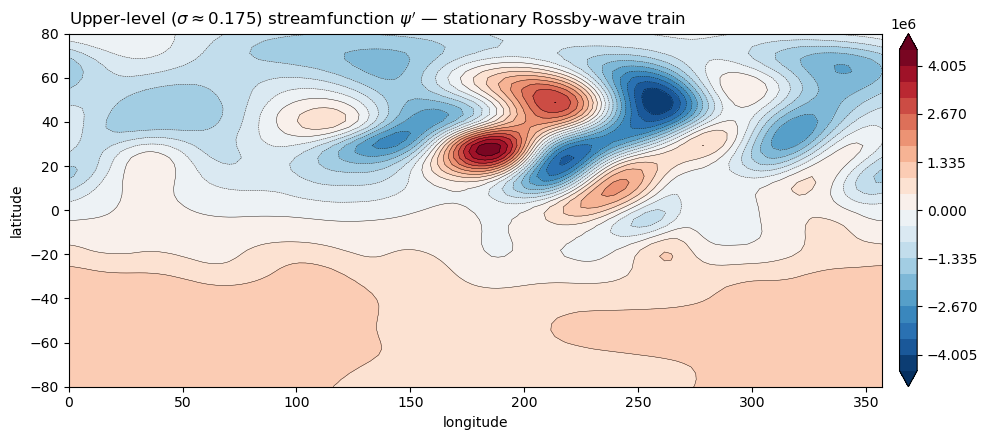

In [5]:
# --- quick look: upper-level (sigma ~ 0.175, ~200 hPa) streamfunction --------
import matplotlib.pyplot as plt

k = int(np.argmin(np.abs(sig - 0.175)))
psi = asnumpy(model.ga.psi[:, :, k]) if hasattr(model.ga, "psi") \
      else asnumpy(model.diagnostics()["psi"][:, :, k])

fig, ax = plt.subplots(figsize=(10, 4.5))
vmax = np.abs(psi).max() or 1.0
cf = ax.contourf(lon, lat, psi, levels=np.linspace(-vmax, vmax, 21),
                 cmap="RdBu_r", extend="both")
ax.contour(lon, lat, psi, levels=np.linspace(-vmax, vmax, 21),
           colors="k", linewidths=0.3)
ax.set_ylim(-80, 80); ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title(r"Upper-level ($\sigma\approx0.175$) streamfunction $\psi'$"
             r" — stationary Rossby-wave train", loc="left")
fig.colorbar(cf, ax=ax, pad=0.02, fraction=0.025)
fig.tight_layout(); plt.show()

## 6. (optional) Save gridded output

In [6]:
# --- (optional) write GrADS + netCDF output ----------------------------------
from pylbm_isca.output import GradsWriter  # NetCDFWriter also available
os.makedirs(os.path.join(root, "out"), exist_ok=True)
# Re-run with a writer attached if you want the full gridded history on disk:
#   w = GradsWriter(os.path.join(root, "out", "realistic.1979.phase1.grd"), sp, vg)
#   model.run(mjo_forcing=mjo, writer=w)
print("final-state grid fields available as model.ga.u / .v / .t / .psi ...")

final-state grid fields available as model.ga.u / .v / .t / .psi ...
